In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv("athlete_events.csv")
region_df=pd.read_csv("noc_regions.csv")

In [3]:
df

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN


In [4]:
df = df[df["Season"] == "Summer"]

In [5]:
region_df

,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN
...,...,...,...
225,YEM,Yemen,NaN
226,YMD,Yemen,South Yemen
227,YUG,Serbia,Yugoslavia
228,ZAM,Zambia,NaN


In [6]:
df=df.merge(region_df,on="NOC",how="left")

In [7]:
df["region"].nunique()

205

In [8]:
df.isnull().sum()

ID             0
Name           0
Sex            0
Age         9189
Height     51857
Weight     53854
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     188464
region       370
notes     218151
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1385)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.sample(5)

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region,notes
123367,75388,"Michael Lawrence ""Mike"" Marsh",M,28.0,178.0,75.0,United States,USA,1996 Summer,1996,Summer,Atlanta,Athletics,Athletics Men's 200 metres,NaN,USA,NaN
13645,8632,Thomas Sydney Battersby,M,24.0,NaN,NaN,Great Britain,GBR,1912 Summer,1912,Summer,Stockholm,Swimming,Swimming Men's 4 x 200 metres Freestyle Relay,Bronze,UK,NaN
130016,79362,Monika Ewa Michalik (Rogien-),F,28.0,167.0,63.0,Poland,POL,2008 Summer,2008,Summer,Beijing,Wrestling,"Wrestling Women's Middleweight, Freestyle",NaN,Poland,NaN
180856,110584,L. Jay Silvester,M,34.0,191.0,114.0,United States,USA,1972 Summer,1972,Summer,Munich,Athletics,Athletics Men's Discus Throw,Silver,USA,NaN
39072,24022,douard Crut,M,23.0,NaN,NaN,France,FRA,1924 Summer,1924,Summer,Paris,Football,Football Men's Football,NaN,France,NaN


In [12]:
df["Medal"].value_counts()

Medal
Gold      11456
Bronze    11409
Silver    11212
Name: count, dtype: int64

In [13]:
df.groupby("NOC")["Medal"].sum()
#so we need to do encoding

NOC
AFG                                         BronzeBronze
AHO                                               Silver
ALB                                                     
ALG    BronzeBronzeSilverGoldBronzeBronzeGoldSilverSi...
AND                                                     
                             ...                        
YEM                                                     
YMD                                                     
YUG    SilverGoldGoldGoldGoldSilverBronzeSilverSilver...
ZAM                                         SilverBronze
ZIM    GoldGoldSilverGoldBronzeSilverGoldSilverSilver...
Name: Medal, Length: 230, dtype: str

In [14]:
pd.get_dummies(df["Medal"]).astype('int32')

,Bronze,Gold,Silver
0,0,0,0
1,0,0,0
2,0,0,0
3,0,1,0
4,0,0,0
...,...,...,...
222547,0,0,0
222548,0,0,0
222549,0,0,0
222550,0,0,0


In [15]:
df=pd.concat([df,pd.get_dummies(df["Medal"],dtype='int32')],axis=1)

In [16]:
df.groupby("NOC")[['Gold','Silver','Bronze']].sum().sort_values("Gold",ascending=False).reset_index()

,NOC,Gold,Silver,Bronze
0,USA,2472,1333,1197
1,URS,832,635,596
2,GBR,635,729,620
3,GER,592,538,649
4,ITA,518,474,454
...,...,...,...,...
225,WIF,0,0,5
226,YEM,0,0,0
227,YAR,0,0,0
228,YMD,0,0,0


In [17]:
medal_tally=df.drop_duplicates(subset=["Team","NOC","Games","Year","City","Sport","Event","Medal"])

In [18]:
medal_tally

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region,notes,Bronze,Gold,Silver
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,China,NaN,0,0,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,China,NaN,0,0,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,Denmark,NaN,0,0,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,Denmark,NaN,0,1,0
4,8,"Cornelia ""Cor"" Aalten (-Strannood)",F,18.0,168.0,NaN,Netherlands,NED,1932 Summer,1932,Summer,Los Angeles,Athletics,Athletics Women's 100 metres,NaN,Netherlands,NaN,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
222528,135553,Galina Ivanovna Zybina (-Fyodorova),F,25.0,168.0,80.0,Soviet Union,URS,1956 Summer,1956,Summer,Melbourne,Athletics,Athletics Women's Shot Put,Silver,Russia,NaN,0,0,1
222530,135553,Galina Ivanovna Zybina (-Fyodorova),F,33.0,168.0,80.0,Soviet Union,URS,1964 Summer,1964,Summer,Tokyo,Athletics,Athletics Women's Shot Put,Bronze,Russia,NaN,1,0,0
222536,135556,Bogusaw Stanisaw Zychowicz,M,19.0,189.0,80.0,Poland,POL,1980 Summer,1980,Summer,Moskva,Swimming,Swimming Men's 100 metres Butterfly,NaN,Poland,NaN,0,0,0
222537,135556,Bogusaw Stanisaw Zychowicz,M,19.0,189.0,80.0,Poland,POL,1980 Summer,1980,Summer,Moskva,Swimming,Swimming Men's 200 metres Butterfly,NaN,Poland,NaN,0,0,0


In [19]:
medal_tally=medal_tally.groupby("NOC")[['Gold','Silver','Bronze']].sum().sort_values("Gold",ascending=False).reset_index()

In [20]:
medal_tally['total']=medal_tally['Gold'] + medal_tally['Silver'] + medal_tally['Bronze']


In [21]:
medal_tally

,NOC,Gold,Silver,Bronze,total
0,USA,1035,802,708,2545
1,URS,394,317,294,1005
2,GBR,278,317,300,895
3,GER,235,261,283,779
4,FRA,234,256,287,777
...,...,...,...,...,...
225,WIF,0,0,2,2
226,YEM,0,0,0,0
227,YAR,0,0,0,0
228,YMD,0,0,0,0


In [22]:
years = df['Year'].unique().tolist()
years.sort()

In [23]:
years

[1896,
 1900,
 1904,
 1906,
 1908,
 1912,
 1920,
 1924,
 1928,
 1932,
 1936,
 1948,
 1952,
 1956,
 1960,
 1964,
 1968,
 1972,
 1976,
 1980,
 1984,
 1988,
 1992,
 1996,
 2000,
 2004,
 2008,
 2012,
 2016]

In [24]:
years.insert(0,'Overall')

In [25]:
years


['Overall',
 1896,
 1900,
 1904,
 1906,
 1908,
 1912,
 1920,
 1924,
 1928,
 1932,
 1936,
 1948,
 1952,
 1956,
 1960,
 1964,
 1968,
 1972,
 1976,
 1980,
 1984,
 1988,
 1992,
 1996,
 2000,
 2004,
 2008,
 2012,
 2016]

In [26]:
country=df['region'].dropna().values.unique().tolist()

In [27]:
country.sort()

In [28]:
country

['Afghanistan',
 'Albania',
 'Algeria',
 'American Samoa',
 'Andorra',
 'Angola',
 'Antigua',
 'Argentina',
 'Armenia',
 'Aruba',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bermuda',
 'Bhutan',
 'Boliva',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Cape Verde',
 'Cayman Islands',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Cook Islands',
 'Costa Rica',
 'Croatia',
 'Cuba',
 'Curacao',
 'Cyprus',
 'Czech Republic',
 'Democratic Republic of the Congo',
 'Denmark',
 'Djibouti',
 'Dominica',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Ethiopia',
 'Fiji',
 'Finland',
 'France',
 'Gabon',
 'Gambia',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',
 'Grenada',
 'Guam',
 'Guatemala',
 'Guinea',
 'Guin

In [29]:
country.insert(0,'Overall')

In [30]:
medal_df=df.drop_duplicates(subset=["Team","NOC","Games","Year","City","Sport","Event","Medal"])

In [31]:
def fetch_medal_tally(year,country):
    medal_df=df.drop_duplicates(subset=["Team","NOC","Games","Year","City","Sport","Event","Medal"])
    flag=0
    if year == 'Overall' and country == 'Overall':
        temp_df=medal_df
    if year == 'Overall' and country != 'Overall':
        flag=1
        temp_df=medal_df[medal_df['region'] == country]
    if year != 'Overall' and country == 'Overall':
        temp_df=medal_df[medal_df['Year'] == int(year)]
    if year != 'Overall' and country != 'Overall':
        temp_df=medal_df[(medal_df['Year'] == int(year)) & (medal_df['region'] == country)]

    if flag == 1:
        x=temp_df.groupby("Year")[['Gold','Silver','Bronze']].sum().sort_values("Year").reset_index()
    else:
        x=temp_df.groupby("region")[['Gold','Silver','Bronze']].sum().sort_values("Gold",ascending=False).reset_index()
    x['total']=x['Gold'] + x['Silver'] + x['Bronze']
    

    return x
    

In [32]:
fetch_medal_tally(year='Overall',country='India')

,Year,Gold,Silver,Bronze,total
0,1900,0,2,0,2
1,1920,0,0,0,0
2,1924,0,0,0,0
3,1928,1,0,0,1
4,1932,1,0,0,1
5,1936,1,0,0,1
6,1948,1,0,0,1
7,1952,1,0,1,2
8,1956,1,0,0,1
9,1960,0,1,0,1


In [33]:

#Overall Analysis:
    
#No. of editions
#No. of cities   
#No. of events/sports   
#No. of athletes   
#participating nations   

In [34]:
df['Year'].unique().shape[0] - 1

28

In [35]:
df['City'].unique().shape[0]

23

In [36]:
df['Sport'].unique().shape[0]

52

In [37]:
df['Event'].unique().shape[0]

651

In [38]:
df.drop_duplicates(subset=["Team","NOC","Games","Year","City","Sport","Event","Medal"]).shape[0] #unique atheletes

105636

In [39]:
df['region'].unique().shape[0]

206

In [40]:
nations_over_time=df.drop_duplicates(['Year','region'])['Year'].value_counts().reset_index().sort_values('Year')

In [41]:
nations_over_time=nations_over_time.rename(columns={'count':'No. of countries'})
nations_over_time

,Year,No. of countries
28,1896,12
22,1900,31
27,1904,14
26,1906,20
25,1908,22
24,1912,29
23,1920,29
21,1924,45
20,1928,46
19,1932,47


In [42]:
nations_over_time

,Year,No. of countries
28,1896,12
22,1900,31
27,1904,14
26,1906,20
25,1908,22
24,1912,29
23,1920,29
21,1924,45
20,1928,46
19,1932,47


In [43]:
import plotly.express as px

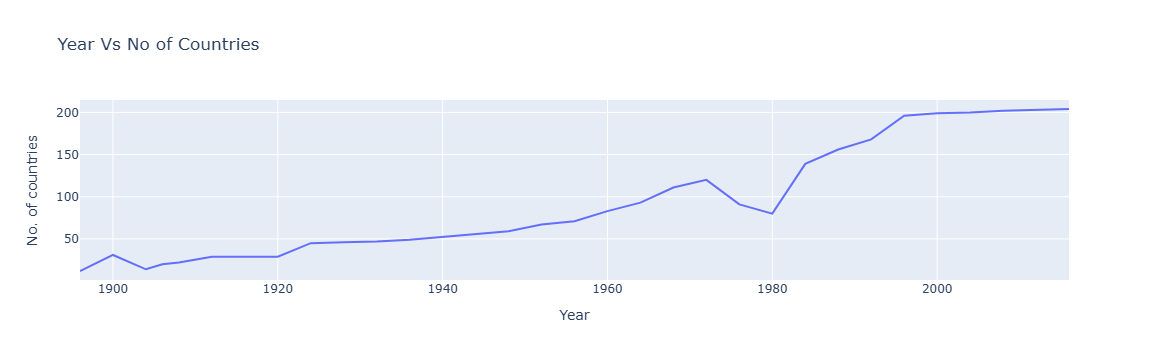

In [44]:
fig = px.line(nations_over_time, x=nations_over_time['Year'], y=nations_over_time["No. of countries"], title="Year Vs No of Countries")
fig.show()

In [45]:
events_over_time=df.drop_duplicates(['Year','Event'])['Year'].value_counts().reset_index().sort_values('Year')

In [46]:
events_over_time

,Year,count
28,1896,43
26,1900,90
25,1904,95
27,1906,74
23,1908,109
24,1912,107
14,1920,158
21,1924,131
22,1928,122
20,1932,131


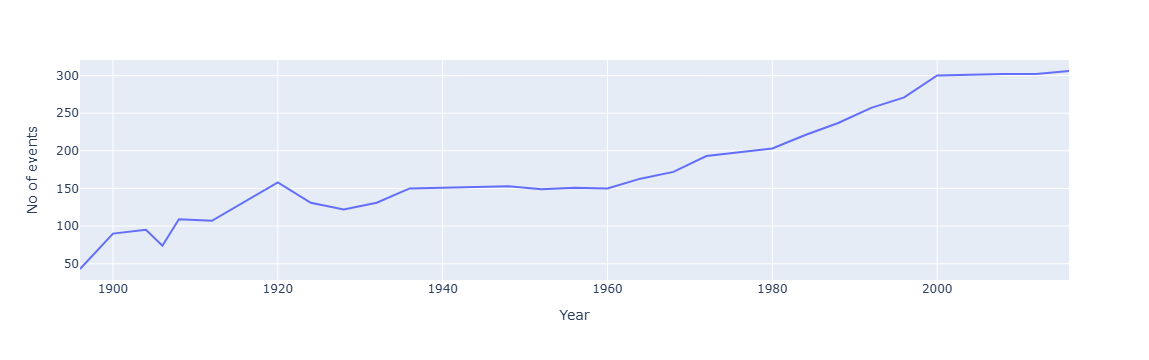

In [47]:
events_over_time=events_over_time.rename(columns={'count':'No of events'})
fig = px.line(events_over_time, x=events_over_time['Year'], y=events_over_time["No of events"])
fig.show()

In [48]:
athletes_over_time=df.drop_duplicates(['Year','Name'])['Year'].value_counts().reset_index().sort_values('Year')
athletes_over_time


,Year,count
28,1896,176
25,1900,1220
27,1904,650
26,1906,841
23,1908,2024
22,1912,2409
21,1920,2675
19,1924,3256
20,1928,3246
24,1932,1922


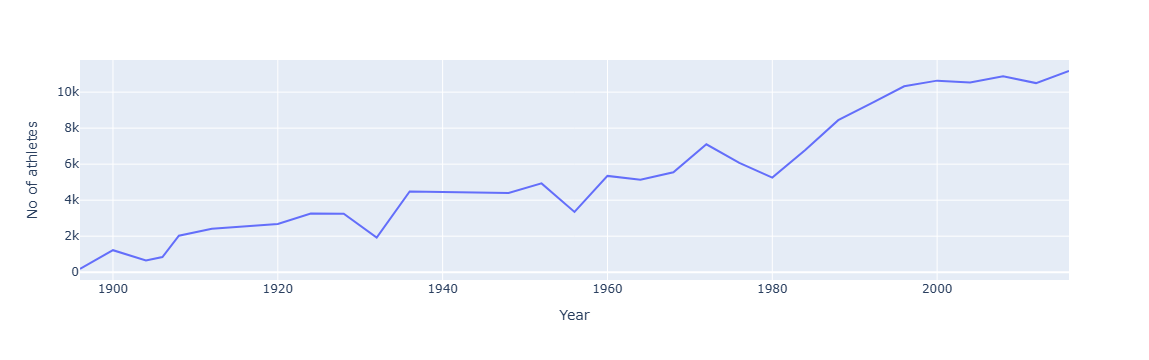

In [49]:
athletes_over_time=athletes_over_time.rename(columns={'count':'No of athletes'})
fig = px.line(athletes_over_time, x=athletes_over_time['Year'], y=athletes_over_time["No of athletes"])
fig.show()

In [50]:
d=df.drop_duplicates(['Year','Sport','Event'])

<Axes: xlabel='Year', ylabel='Sport'>

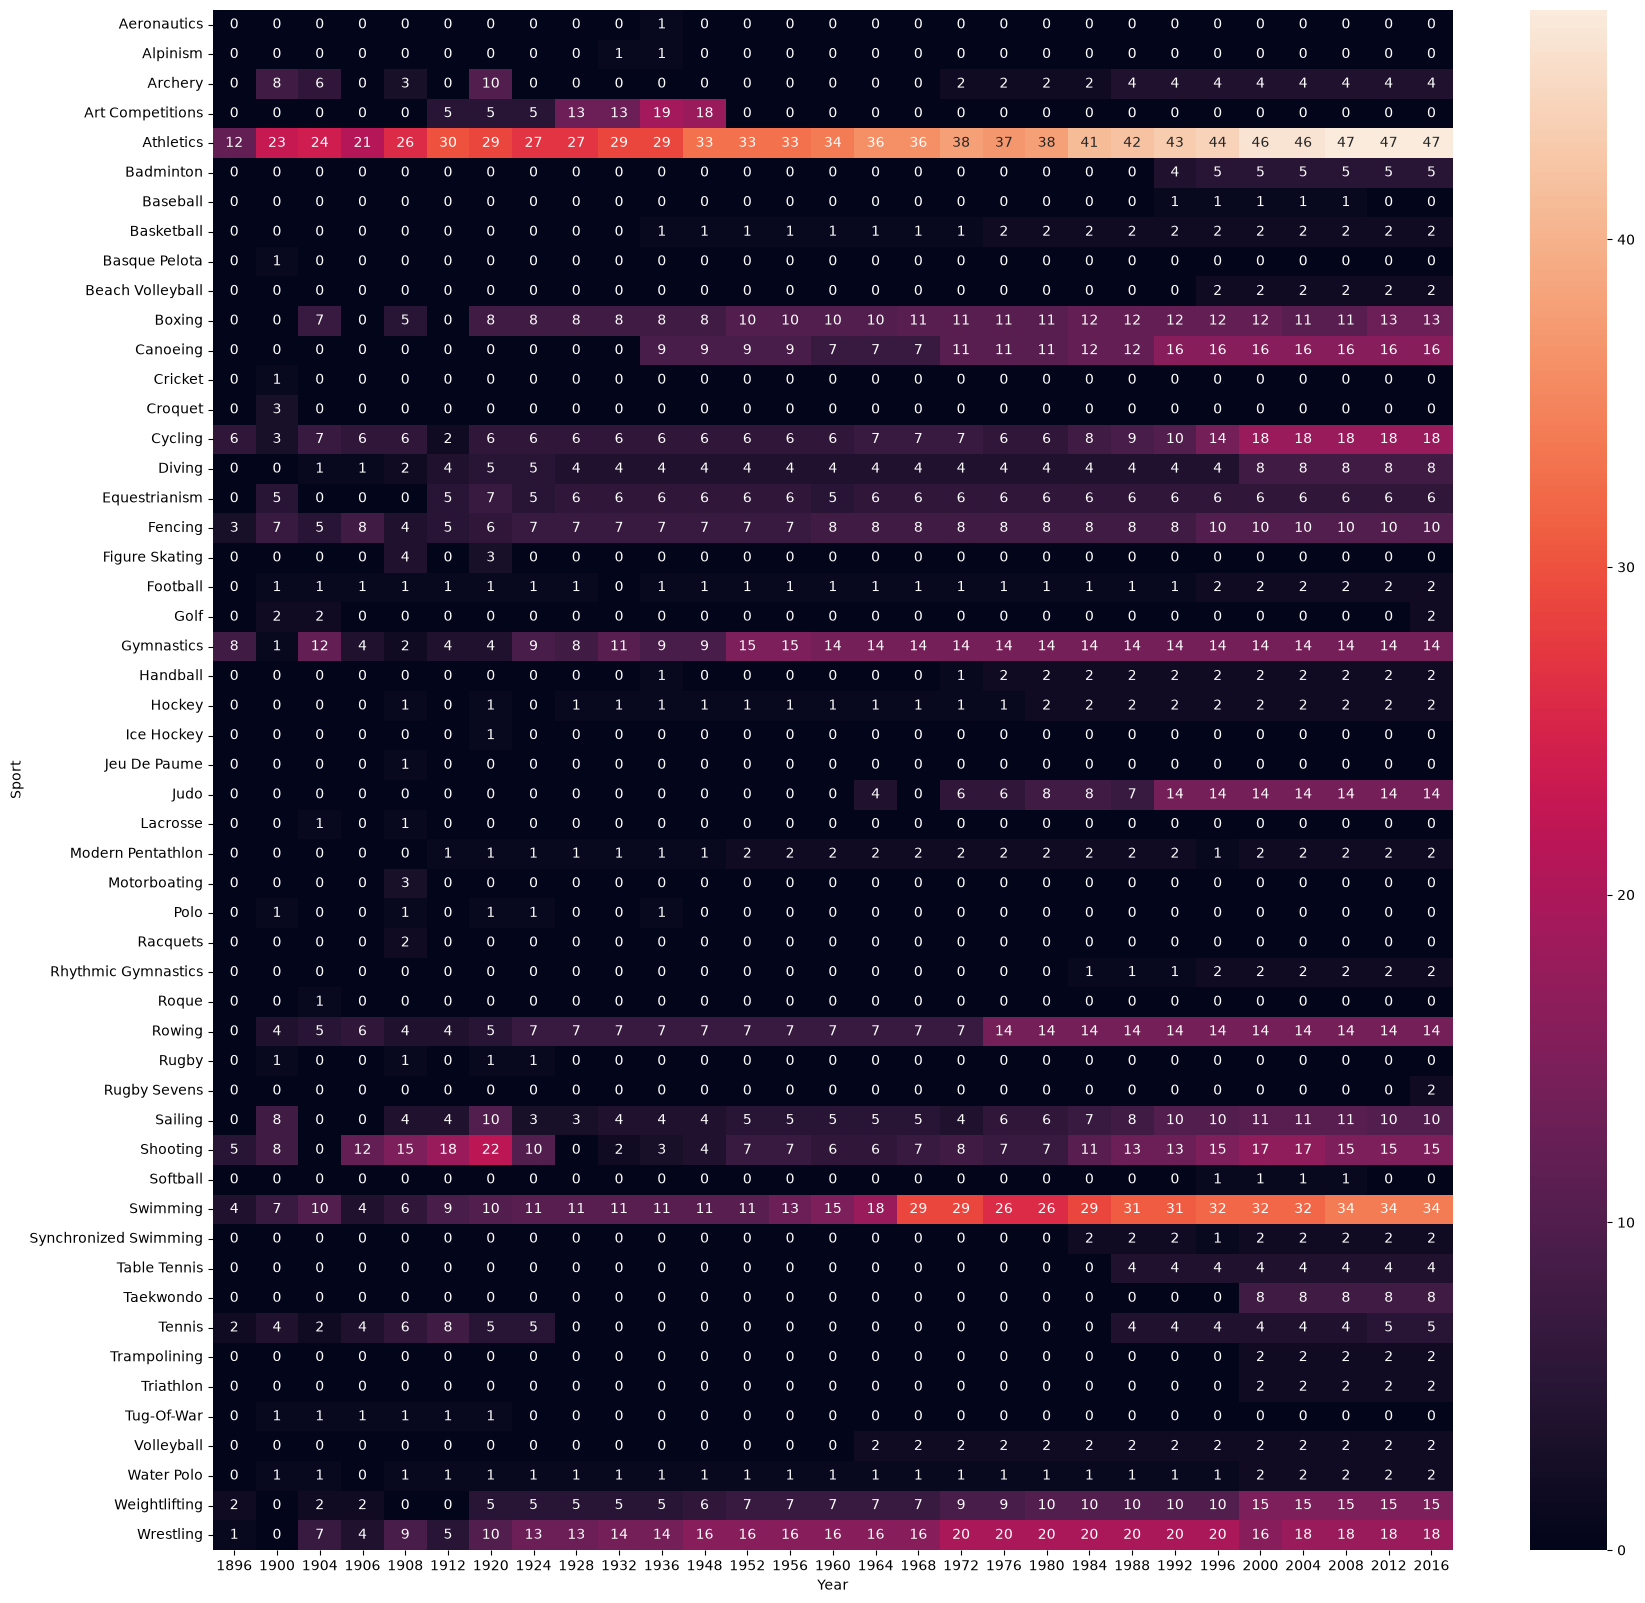

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(20,20))
sns.heatmap(d.pivot_table(index='Sport',columns='Year',values='Event',aggfunc='count').fillna(0).astype('int'),annot=True)

In [52]:
#finding top athlets from sport given by input
def find_top(dd,sport):
    if sport != 'Overall':
        temp_df=dd[dd['Sport'] == sport]
    else:
        temp_df=dd
    temp_df = temp_df.dropna(subset=["Medal"])
    top_athletes = (
        temp_df["Name"].value_counts().reset_index().head(15).merge(df,on='Name',how='left')[['Name','count','Sport','region','ID']].drop_duplicates()
    )
    top_athletes.rename(columns={'count':'Medals'},inplace=True)
    return top_athletes
    

In [53]:
find_top(df,"Swimming")

,Name,Medals,Sport,region,ID
0,"Michael Fred Phelps, II",28,Swimming,USA,94406
30,Natalie Anne Coughlin (-Hall),12,Swimming,USA,23426
42,Ryan Steven Lochte,12,Swimming,USA,70965
56,"Jennifer Elisabeth ""Jenny"" Thompson (-Cumpelik)",12,Swimming,USA,119922
73,"Dara Grace Torres (-Hoffman, -Minas)",12,Swimming,USA,121258
86,"Matthew Nicholas ""Matt"" Biondi",11,Swimming,USA,11642
98,Mark Andrew Spitz,11,Swimming,USA,113912
110,"Gary Wayne Hall, Jr.",10,Swimming,USA,45039
120,Franziska van Almsick,10,Swimming,Germany,124146
143,Shirley Frances Babashoff,9,Swimming,USA,6430


In [54]:
def country_wise(df, country):
    # 1. Drop rows without medals
    temp_df = df.dropna(subset=["Medal"])

    # 2. Drop duplicate team/event rows so team members aren't overcounted  ...this is solving the problem of multiple team members of same team giving same medal output
    temp_df = temp_df.drop_duplicates(
        subset=[
            "Team",
            "NOC",
            "Games",
            "Year",
            "City",
            "Sport",
            "Event",
            "Medal",
        ]
    )

    # 3. Filter by country
    temp_df = temp_df[temp_df["region"] == country]

    # 4. Group by Year and SUM the actual medal columns instead of counting rows
    new_df = (
        temp_df.groupby("Year")[["Gold", "Silver", "Bronze"]]
        .sum()
        .reset_index()
    )

    # 5. Calculate total
    new_df["total"] = (
        new_df["Gold"] + new_df["Silver"] + new_df["Bronze"]
    )

    return new_df

In [55]:
new_df=country_wise(df,"India")

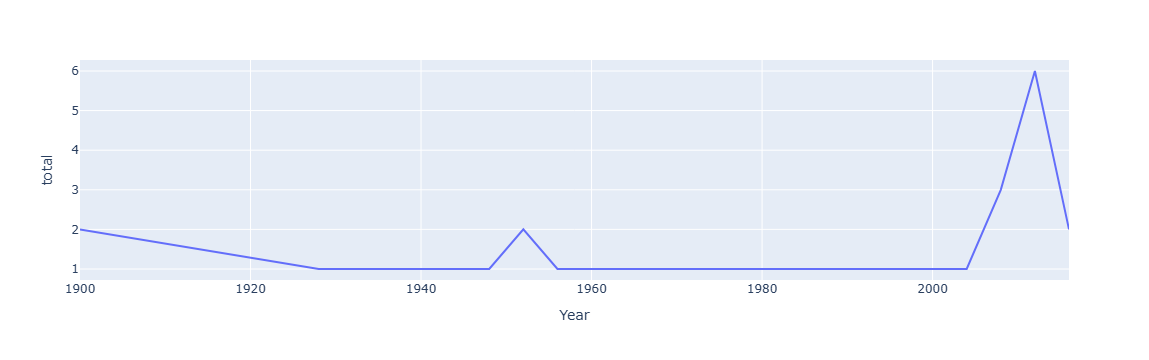

In [56]:
fig = px.line(new_df, x=new_df['Year'], y=new_df["total"])
fig.show()

In [57]:
country_wise(df,'USA')

,Year,Gold,Silver,Bronze,total
0,1896,11,6,2,19
1,1900,21,16,17,54
2,1904,76,79,76,231
3,1906,12,5,6,23
4,1908,22,12,12,46
5,1912,26,18,19,63
6,1920,41,27,27,95
7,1924,45,27,27,99
8,1928,22,18,16,56
9,1932,44,36,30,110


In [58]:
temp_df=df.dropna(subset=['Medal'])

In [59]:
temp_df=temp_df.drop_duplicates(subset=[
            "Team",
            "NOC",
            "Games",
            "Year",
            "City",
            "Sport",
            "Event",
            "Medal",
        ])

In [60]:
newdf=temp_df[['Name','Sport','Medal','Year']]

In [61]:
new_df=temp_df[temp_df['region'] == 'USA']
#new_df=newdf.groupby('Year')['Medal'].count().reset_index()

In [62]:
new_df.pivot_table(index='Sport',columns='Year',values='Medal',aggfunc='count').fillna(0).astype(int)


Year,1896,1900,1904,1906,1908,1912,1920,1924,1928,1932,...,1976,1984,1988,1992,1996,2000,2004,2008,2012,2016
Sport,,,,,,,,,,,,,,,,,,,,,
Archery,0,0,16,0,1,0,0,0,0,0,...,2,2,3,0,2,2,0,0,1,2
Art Competitions,0,0,0,0,0,1,0,0,0,7,...,0,0,0,0,0,0,0,0,0,0
Athletics,16,39,65,22,33,41,29,32,25,35,...,22,40,26,30,23,16,25,23,28,32
Baseball,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,1,0,0
Basketball,0,0,0,0,0,0,0,0,0,0,...,2,2,2,2,2,2,2,2,2,2
Beach Volleyball,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,1,2,2,2,1
Boxing,0,0,18,0,0,0,4,6,3,5,...,7,11,8,3,6,4,2,1,2,3
Canoeing,0,0,0,0,0,0,0,0,0,0,...,0,1,2,3,1,0,1,0,0,0
Cycling,0,1,21,0,0,2,0,0,0,0,...,0,9,1,2,3,2,2,5,4,5


In [63]:

#finding top athlets from country given by input
def find_top_bycountry(dd,country):
    if country != 'Overall':
        temp_df=dd[dd['region'] == country]
    else:
        temp_df=dd
    temp_df = temp_df.dropna(subset=["Medal"])
    top_athletes = (
        temp_df["Name"].value_counts().reset_index().head(15).merge(dd,on='Name',how='left')[['Name','count','Sport','ID']].drop_duplicates()
    )
    top_athletes.rename(columns={'count':'Medals'},inplace=True)
    return top_athletes

In [64]:
find_top_bycountry(df,'India')

,Name,Medals,Sport,ID
0,Leslie Walter Claudius,4,Hockey,21912
4,Udham Singh Kular,4,Hockey,111159
8,Richard James Allen,3,Hockey,2864
11,Dhyan Chand Bais,3,Hockey,19716
14,Ranganathan Francis,3,Hockey,36678
17,Shankar Pillay Laxman,3,Hockey,67372
20,"Victor John ""V. J."" Peter",3,Hockey,93798
23,Balbir Singh,3,Hockey,111012
24,Balbir Singh,3,Hockey,111013
25,Balbir Singh,3,Hockey,111014


In [65]:
#4;Athlete analysis
import plotly.figure_factory as ff

In [66]:
athlete_df=df.drop_duplicates(subset=['Name','region'])

In [67]:
x1=athlete_df['Age'].dropna()
x2=athlete_df[athlete_df['Medal'] == 'Gold']['Age'].dropna()
x3=athlete_df[athlete_df['Medal'] == 'Silver']['Age'].dropna()
x4=athlete_df[athlete_df['Medal'] == 'Bronze']['Age'].dropna()

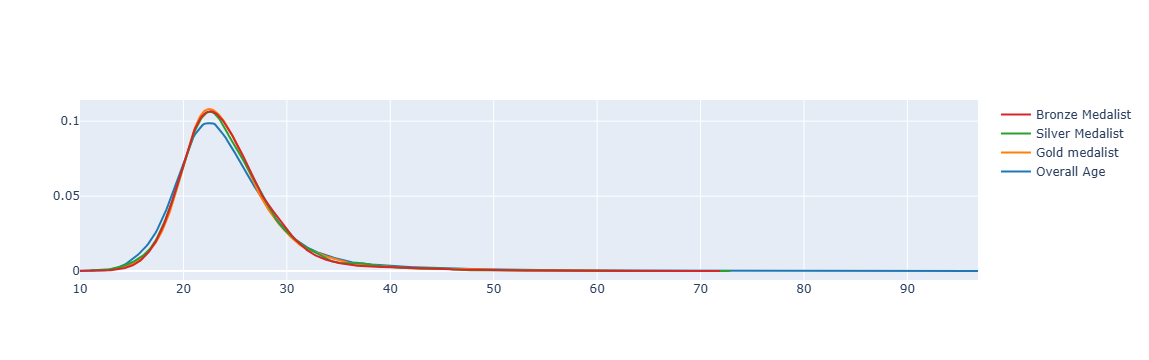

In [68]:
fig=ff.create_distplot([x1,x2,x3,x4],["Overall Age","Gold medalist","Silver Medalist","Bronze Medalist"],show_hist=False,show_rug=False)
fig.show()

In [79]:
#which age gets u a gold medal in each sport
x = []
name = []
famous_sports = [
    'Basketball', 'Judo', 'Football', 'Tug-Of-War', 'Athletics',
    'Swimming', 'Badminton', 'Sailing', 'Gymnastics',
    'Art Competitions', 'Handball', 'Weightlifting', 'Wrestling',
    'Water Polo', 'Hockey', 'Rowing', 'Fencing',
    'Shooting', 'Boxing', 'Taekwondo', 'Cycling', 'Diving', 'Canoeing',
    'Tennis', 'Golf', 'Softball', 'Archery',
    'Volleyball', 'Synchronized Swimming', 'Table Tennis', 'Baseball',
    'Rhythmic Gymnastics', 'Rugby Sevens',
    'Beach Volleyball', 'Triathlon', 'Rugby', 'Polo', 'Ice Hockey'
]

for sport in famous_sports:
    temp_df = athlete_df[athlete_df['Sport'] == sport] #that sport
    x.append(temp_df[temp_df['Medal'] == 'Gold']['Age'].dropna()) #age w gold medal
    name.append(sport) 

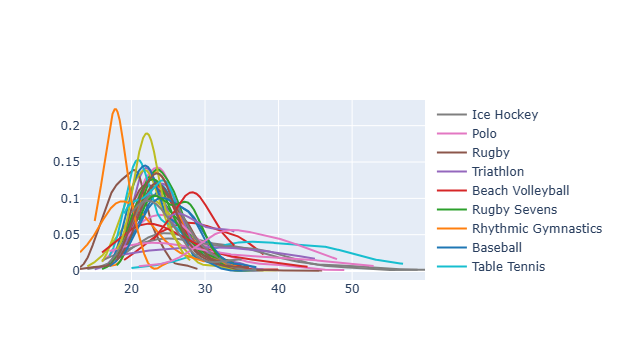

In [80]:
ff.create_distplot(x, name, show_hist=False, show_rug=False)

In [81]:
athlete_df['Medal'].fillna('No medal',inplace=True)

C:\Users\KISHORI CHARPE\AppData\Local\Temp\ipykernel_6108\2600687759.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  athlete_df['Medal'].fillna('No medal',inplace=True)


0         No medal
1         No medal
2         No medal
3             Gold
4         No medal
            ...   
222544      Bronze
222546    No medal
222548    No medal
222549    No medal
222551    No medal
Name: Medal, Length: 116885, dtype: str

<Axes: xlabel='Height', ylabel='Weight'>

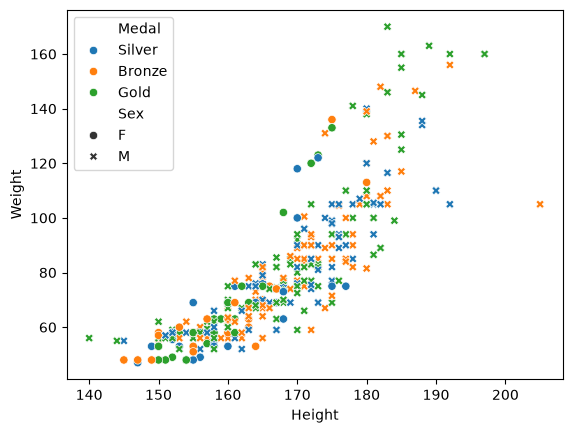

In [88]:
temp_df=athlete_df[athlete_df['Sport']== 'Weightlifting']
sns.scatterplot(x=temp_df['Height'],y=temp_df['Weight'],hue=temp_df['Medal'],style=temp_df['Sex'])

In [93]:
men=athlete_df[athlete_df['Sex']=='M'].groupby('Year')['Name'].count().reset_index()
women=athlete_df[athlete_df['Sex']=='F'].groupby('Year')['Name'].count().reset_index()

In [101]:
final=men.merge(women,on='Year',how='left')
final.rename(columns={"Name_x":"Male","Name_y":"Female"},inplace=True)

In [102]:
final

,Year,Male,Female
0,1896,174,NaN
1,1900,1181,23.0
2,1904,629,6.0
3,1906,759,6.0
4,1908,1772,44.0
5,1912,1978,53.0
6,1920,2280,73.0
7,1924,2535,132.0
8,1928,2342,285.0
9,1932,1382,162.0


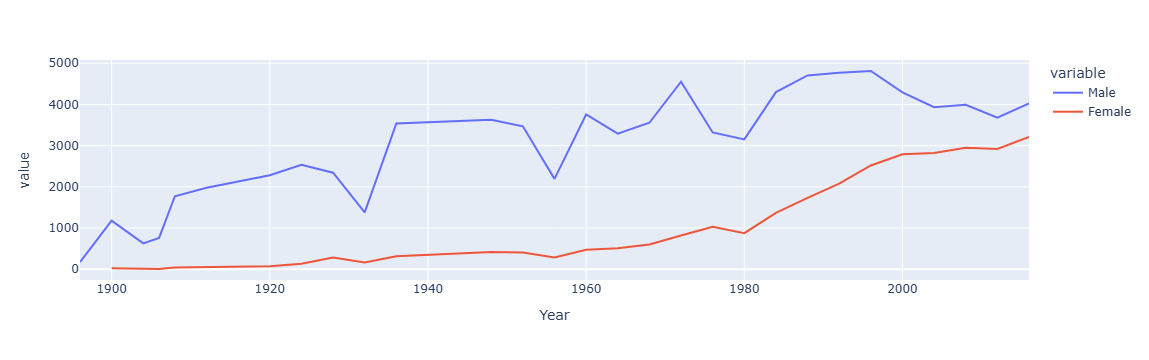

In [103]:
px.line(final,x='Year',y=['Male','Female'])